# Exploring Mathematics Student Performance
## Grades, weekly study time, and school absences

**Author — Bismark Gawu**

This exploratory analysis examines 395 mathematics student records from two secondary schools in Portugal. School reports and questionnaires supplied the academic, demographic, social, and school-related information. We use the Mathematics subject file, `student-mat.csv`.

### Questions
1. How are final Mathematics grades distributed?
2. How do average final grades differ across weekly study-time categories?
3. How do grades differ between students with 0–10 absences and those with more than 10?

### Data source and attribution
Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T

Dataset documentation — https://archive.ics.uci.edu/dataset/320/student+performance

The dataset is available under CC BY 4.0 — https://creativecommons.org/licenses/by/4.0/ . Credit the dataset creator when redistributing the CSV. I completed the initial analysis and used AI assistance to review the code, organise the notebook, and refine the written explanations as part of a beginner Python learning project.
### Running this notebook
Place the original `student-mat.csv` in the same folder as this notebook. Install pandas and Matplotlib in the selected Python environment, then restart the kernel and run all cells in order. All file references are relative to the working folder. Saved outputs are included for readers browsing GitHub.


## 1. Load and inspect the data
`read_csv()` reads the semicolon-separated file into a DataFrame. A row represents one student record for the Mathematics subject. We retain the complete table throughout the analysis and use `.head()` only to display previews.


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Display formatting changes appearance while retaining full calculation precision.
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11})

mathematics_students = pd.read_csv("student-mat.csv", sep=";")
display(mathematics_students.head())
print("Dataset shape:", mathematics_students.shape)
print("pandas version:", pd.__version__)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Dataset shape: (395, 33)
pandas version: 3.0.3


The file contains **395 rows and 33 columns**. Each row represents a mathematics student record from one of two secondary schools in Portugal.

| Column | Meaning |
|---|---|
| `age` | Age in years |
| `studytime` | Ordered weekly study-time category |
| `absences` | Recorded number of school absences |
| `G3` | Final mathematics grade on a 0–20 scale |

| Study-time code | Weekly study time, as documented by UCI |
|---|---|
| 1 | Less than 2 hours |
| 2 | 2–5 hours |
| 3 | 5–10 hours |
| 4 | More than 10 hours |

Study-time codes identify groups. `G3` records an individual's final grade, and means are calculated across records.


In [13]:
selected_columns = ["age", "studytime", "absences", "G3"]
display(mathematics_students[selected_columns].head())


,age,studytime,absences,G3
0,18,2,6,6
1,17,2,4,6
2,15,2,10,10
3,15,3,2,15
4,16,2,4,10


The first record describes an 18-year-old in study-time category 2, with six recorded absences and a final mathematics grade of 6 out of 20.

## 2. Check data quality
`.isna()` marks missing entries and `.sum()` counts them by column. This check uses all 395 records. Data types, exact duplicates, and the selected fields' ranges provide additional checks before analysis.


In [14]:
missing_counts = mathematics_students.isna().sum()
display(missing_counts.rename("Missing_values").to_frame())
display(mathematics_students[selected_columns].dtypes.rename("Data_type").to_frame())
print("Exact duplicate rows:", mathematics_students.duplicated().sum())
print("Study-time codes:", sorted(mathematics_students["studytime"].unique()))
display(mathematics_students[selected_columns].agg(["min", "max"]))


,Missing_values
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


,Data_type
age,int64
studytime,int64
absences,int64
G3,int64


Exact duplicate rows: 0
Study-time codes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


,age,studytime,absences,G3
min,15,1,0,0
max,22,4,75,20


All 33 columns contain zero pandas-recognised missing values, and there are zero exact duplicate rows. The four selected fields are integer-valued. Ages range from 15 to 22, study-time codes from 1 to 4, absences from 0 to 75, and final grades from 0 to 20.

Zero grades are retained as observed outcomes within the documented grading scale. The available records do not establish why an individual received zero. Matching values in a few selected columns would be insufficient evidence to remove a student record.

## 3. Summarise final mathematics grades
The mean is total grade points divided by the number of records. The median is the middle sorted grade. The mode is the most frequent grade. We also count grades below, equal to, and above the exact mean to distinguish the mean from a dividing point that splits a group in half.


In [15]:
final_grades = mathematics_students["G3"]
number_of_students = len(mathematics_students)
grade_summary = pd.DataFrame({
    "Measure": ["Student records", "Mean grade", "Median grade", "Lowest grade", "Highest grade"],
    "Value": [number_of_students, final_grades.mean(), final_grades.median(),
              final_grades.min(), final_grades.max()]
})
display(grade_summary)

# Include every possible grade, including grades with no records.
grade_counts = final_grades.value_counts().reindex(range(21), fill_value=0).sort_index()
display(grade_counts.rename_axis("Final_grade").rename("Student_count").to_frame())
most_frequent_count = grade_counts.max()
modal_grades = grade_counts[grade_counts == most_frequent_count].index.tolist()
print("Most common grade(s):", modal_grades)
print("Students receiving each modal grade:", most_frequent_count)

# Compare every grade with the exact mean, before display rounding.
print("Below the mean:", (final_grades < final_grades.mean()).sum())
print("Equal to the mean:", (final_grades == final_grades.mean()).sum())
print("Above the mean:", (final_grades > final_grades.mean()).sum())


,Measure,Value
0,Student records,395.00
1,Mean grade,10.42
2,Median grade,11.00
3,Lowest grade,0.00
4,Highest grade,20.00


,Student_count
Final_grade,
0,38
1,0
2,0
3,0
4,1
5,7
6,15
7,9
8,32


Most common grade(s): [10]
Students receiving each modal grade: 56
Below the mean: 186
Equal to the mean: 0
Above the mean: 209


The mean grade is **10.42 out of 20**, the median is **11**, and the most common grade is **10**, received by **56 students (14.18%)**. The range is **0–20**, with **38 zero grades** and one grade of 20.

There are **186 grades below the exact mean**, **209 above it**, and zero equal to it. The mean therefore does not split the students into equal-sized groups. With 395 grades, the median is the 198th value after sorting. Ties can occur on both sides of that position.


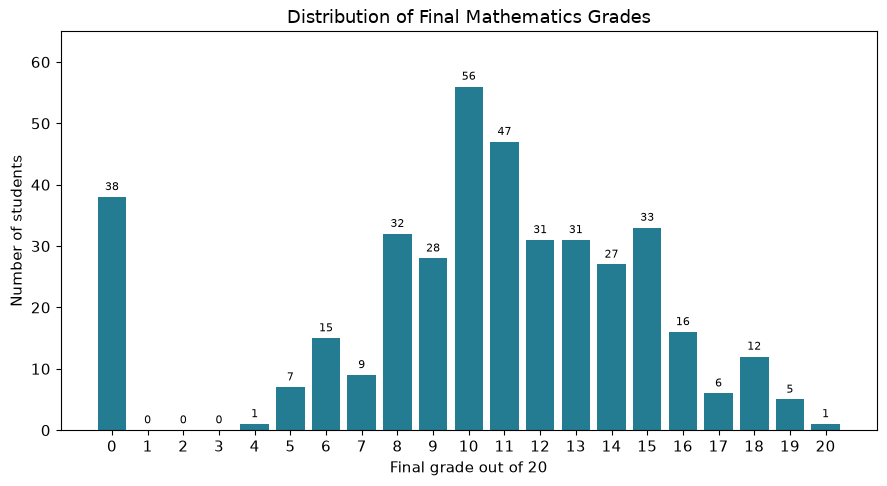

In [16]:
fig, ax = plt.subplots()
bars = ax.bar(grade_counts.index, grade_counts.values, color="#237c91")
ax.set(title="Distribution of Final Mathematics Grades",
       xlabel="Final grade out of 20", ylabel="Number of students")
ax.set_xticks(range(21))
ax.set_ylim(0, 65)
ax.bar_label(bars, padding=3, fontsize=8)
fig.tight_layout()
plt.show()


Grade 10 has the tallest bar with 56 students, followed by grade 11 with 47. The 38 records at grade zero form another visible feature of the distribution. Grades 1, 2, and 3 have zero records, and the counts vary across the remaining grades. The chart shows the full 0–20 scale, including empty grade positions.

## 4. Compare weekly study-time groups
`groupby()` collects records sharing a study-time code. `.agg()` produces student counts and means together. Calculations retain full precision, with display rounded to two decimal places.


In [17]:
studytime_labels = {
    1: "Under 2 hours", 2: "2–5 hours", 3: "5–10 hours", 4: "Over 10 hours"
}
studytime_summary = mathematics_students.groupby("studytime")["G3"].agg(
    Student_count="size", Average_grade="mean"
)
studytime_summary["Weekly_study_time"] = studytime_summary.index.map(studytime_labels)
studytime_summary = studytime_summary[["Weekly_study_time", "Student_count", "Average_grade"]]
display(studytime_summary)
assert studytime_summary["Student_count"].sum() == number_of_students
print("Group counts cover all", number_of_students, "records.")


,Weekly_study_time,Student_count,Average_grade
studytime,,,
1,Under 2 hours,105,10.05
2,2–5 hours,198,10.17
3,5–10 hours,65,11.40
4,Over 10 hours,27,11.26


Group counts cover all 395 records.


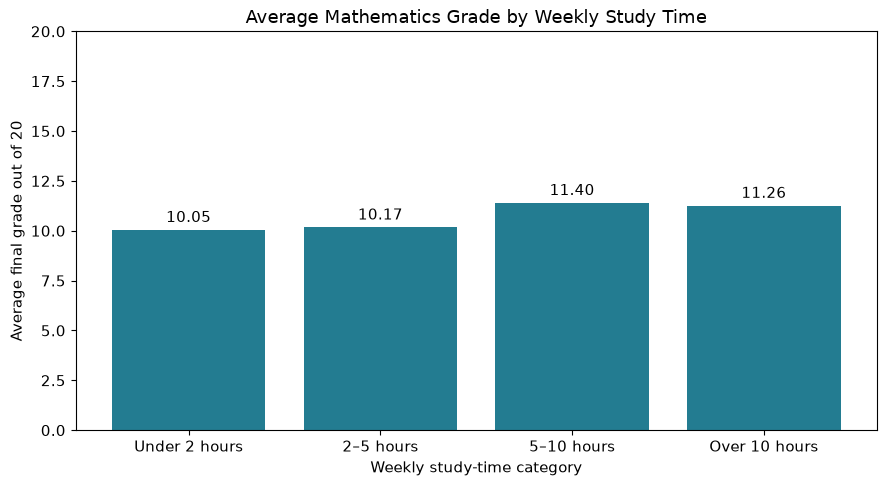

In [18]:
fig, ax = plt.subplots()
bars = ax.bar(studytime_summary["Weekly_study_time"],
              studytime_summary["Average_grade"], color="#237c91")
ax.set(title="Average Mathematics Grade by Weekly Study Time",
       xlabel="Weekly study-time category", ylabel="Average final grade out of 20", ylim=(0, 20))
ax.bar_label(bars, fmt="%.2f", padding=3)
fig.tight_layout()
plt.show()


The **2–5 hours** group is the largest, containing **198 students (50.13%)**, and has an average final grade of **10.17**. The group studying under two hours contains **105 students** and averages **10.05**.

The **5–10 hours** group contains **65 students** and has the highest mean, **11.40**. The **27 students** reporting more than ten hours average **11.26**, approximately **0.14 points lower**. Thus, the mean increases through the first three categories, then decreases slightly in the fourth.

These groups contain different numbers of students. An individual grade can have greater influence on the mean of the smallest group. The summaries describe an association between reported study time and final grades. School, previous achievement, and other characteristics may contribute to the differences. Statistical significance and the effect of increasing an individual's study time have not been estimated here.

## 5. Explore absences and grades
Each dot places a student record using absence count horizontally and final grade vertically. Transparency helps with overlapping dots, although multiple records can still share one location.


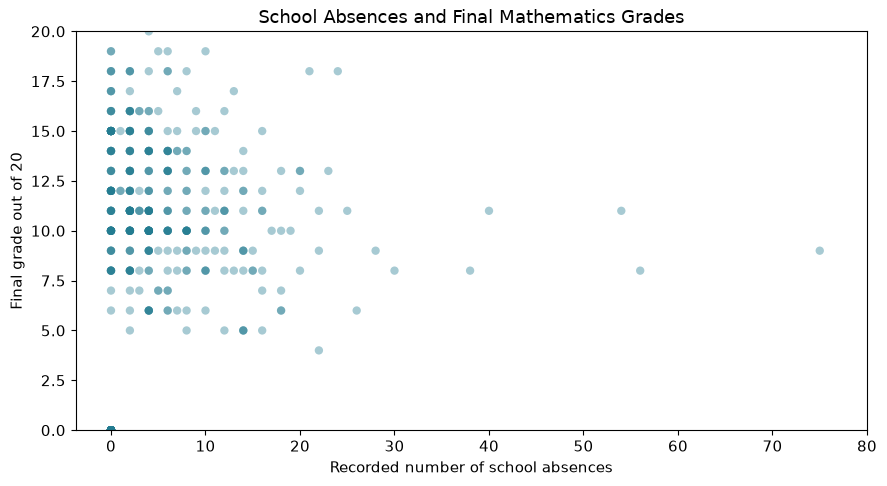

In [19]:
fig, ax = plt.subplots()
ax.scatter(mathematics_students["absences"], mathematics_students["G3"],
           alpha=0.4, color="#237c91", edgecolors="none")
ax.set(title="School Absences and Final Mathematics Grades",
       xlabel="Recorded number of school absences", ylabel="Final grade out of 20", ylim=(0, 20))
ax.set_xticks(range(0, 81, 10))
fig.tight_layout()
plt.show()


Most records cluster at low absence counts, with fewer observations at higher counts and some records extending to **75 absences**. Within the 0–10 absences group, grades span **0–20**, showing that students with similar absence counts can have very different outcomes. The concentration of points at low absence counts describes attendance frequency, while the vertical spread describes grade variation.

### Compare two absence groups
We choose **10 absences** as an exploratory cutoff. Its use here is an analysis choice, without an established attendance-policy meaning. The two conditions include every record in exactly one group.


In [20]:
low_absence_students = mathematics_students[mathematics_students["absences"] <= 10]
high_absence_students = mathematics_students[mathematics_students["absences"] > 10]

low_absence_mean = low_absence_students["G3"].mean()
high_absence_mean = high_absence_students["G3"].mean()
absence_summary = pd.DataFrame({
    "Absence_group": ["0–10 absences", "Over 10 absences"],
    "Student_count": [len(low_absence_students), len(high_absence_students)],
    "Percentage": [len(low_absence_students) / number_of_students * 100,
                   len(high_absence_students) / number_of_students * 100],
    "Average_grade": [low_absence_mean, high_absence_mean]
})
display(absence_summary)
# Subtract the original means to avoid rounding before the calculation.
grade_difference = low_absence_mean - high_absence_mean
print(f"Low-absence mean minus high-absence mean: {grade_difference:.2f} grade points")
assert absence_summary["Student_count"].sum() == number_of_students
assert abs(absence_summary["Percentage"].sum() - 100) < 0.000001
print("Counts cover all records and percentages total 100%.")

# Inspect the zero-grade records without removing them.
zero_grade_students = mathematics_students[mathematics_students["G3"] == 0]
print("Zero-grade records:", len(zero_grade_students))
print("Zero-grade records with zero absences:", (zero_grade_students["absences"] == 0).sum())
print("Low-absence grade range:", low_absence_students["G3"].min(), "to", low_absence_students["G3"].max())


,Absence_group,Student_count,Percentage,Average_grade
0,0–10 absences,329,83.29,10.47
1,Over 10 absences,66,16.71,10.15


Low-absence mean minus high-absence mean: 0.32 grade points
Counts cover all records and percentages total 100%.
Zero-grade records: 38
Zero-grade records with zero absences: 38
Low-absence grade range: 0 to 20


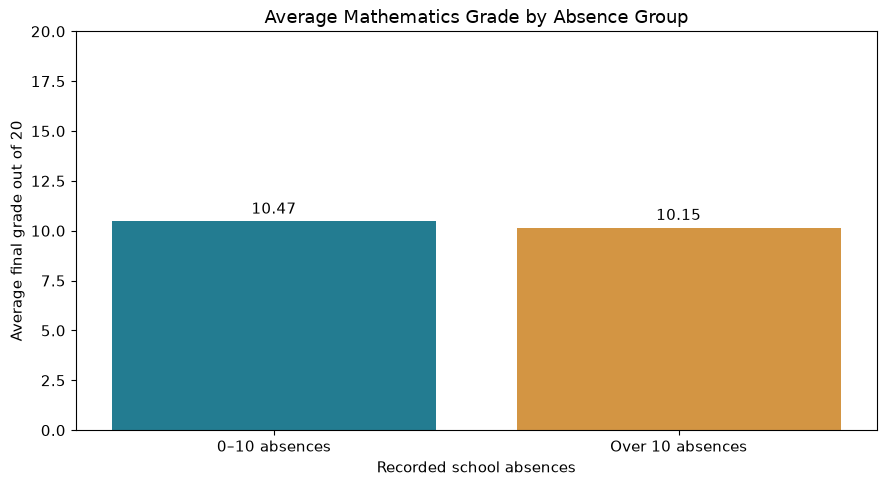

In [21]:
fig, ax = plt.subplots()
bars = ax.bar(absence_summary["Absence_group"], absence_summary["Average_grade"],
              color=["#237c91", "#d39543"])
ax.set(title="Average Mathematics Grade by Absence Group",
       xlabel="Recorded school absences", ylabel="Average final grade out of 20", ylim=(0, 20))
ax.bar_label(bars, fmt="%.2f", padding=3)
fig.tight_layout()
plt.show()


The **329 students with 0–10 absences (83.29%)** average **10.47 out of 20**. The **66 students with more than ten absences (16.71%)** average **10.15**. Subtracting the original means produces a difference of approximately **0.32 grade points**, with the low-absence group higher.

The bars appear similar on the full grading scale. This split gives only a small descriptive difference and does not summarise every possible pattern in the scatter plot. The group sizes also differ substantially.

All **38 zero-grade records have zero recorded absences**, so they belong to the low-absence group and lower its average. The records alone do not explain this combination. We retain those observations and report their presence rather than assume their cause. Further work could investigate their context and examine how the comparison changes under clearly documented alternative analyses.


## 6. Conclusion
This exploratory analysis examined 395 mathematics student records from two secondary schools in Portugal. Final grades averaged 10.42 out of 20, with a median of 11 and an observed range of 0–20. The most frequent grade was 10, received by 56 students. A further 38 records had final grades of zero, making these outcomes an important feature of the distribution.

The highest study-time group mean was 11.40 among 65 students reporting 5–10 hours per week. Students reporting more than ten hours averaged 11.26, so the means did not increase consistently across all categories. Unequal group sizes warrant care when comparing these averages.

Using ten absences as the chosen cutoff, 329 students had at most ten absences and averaged 10.47. The remaining 66 averaged 10.15, a difference of approximately 0.32 points. All zero-grade records belonged to the low-absence group. These results describe associations within the observed data. Other student characteristics and the context of zero grades require investigation before explaining the differences or extending the findings to other schools.

## 7. Limitations and reproducibility
- The data cover two Portuguese schools. Additional evidence is needed to generalise the patterns.
- Study time is recorded in questionnaire categories, giving approximate groups of weekly hours.
- Means conceal variation within groups. Previous achievement, school, and background characteristics may influence comparisons.
- Ten absences is an exploratory cutoff. Alternative cutoffs may produce different summaries.
- Zero grades remain part of the analysis, and all 38 occur at zero recorded absences. Their individual circumstances are unavailable here.
- This descriptive project does not estimate statistical significance or causal effects.
- The original CSV is kept intact. All outputs can be regenerated by running the cells in sequence.

### Skills demonstrated
CSV loading, DataFrame inspection, missing-value checks, descriptive statistics, filtering, grouping, percentage calculations, bar charts, scatter plots, and interpretation of findings.
